<a href="https://colab.research.google.com/github/vzavala/DesignOfExperiments/blob/main/Python/ch6_neuralnet_basis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Perceptrons as basis functions (Victor Z and Ugochukwu Ikegwu, UW-Madison, 2024).

| Slides | Python | Meaning |
|---|---|---|
| $a_j=\theta^I_{j,1}x+\theta^I_{j,0}$ | `theta_I1[j] * x + theta_I0[j]` | evidence of perceptron $j$ |
| $h_j(a)=1/(1+e^{-a_j})$ | `h(a)` | sigmoidal activation (basis function) |
| $\hat{y}=\sum_j\theta^O_jh(a_j)$ | `m(theta, x)` | NN output |
| $\theta=(\theta^I_{\cdot,1},\theta^O,\theta^I_{\cdot,0})$ | `theta` | the 18 parameters ($N=6$ perceptrons) |
| $\mathcal{H}\approx\mathcal{J}^T\mathcal{J}$ | `H` | Gauss-Newton Hessian |

**Note:** This notebook reproduces Example 6.27 (Section 6.7.1) of *Statistics for Chemical Engineers*: a small neural network seen as a model built from basis functions.

number of parameters = 18


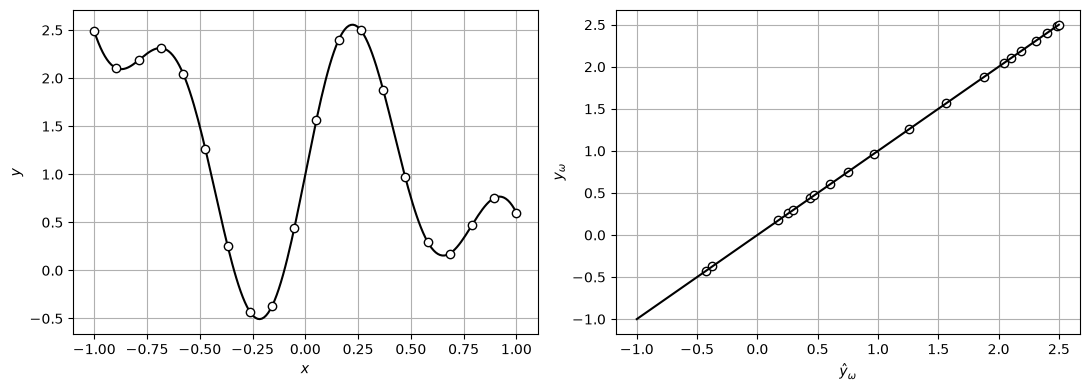

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import least_squares

N = 6                                            # perceptrons
x = np.linspace(-1, 1, 20)
y = np.sin(4*x) + np.sin(8*x) + np.exp(-x)

def h(a):
    return 1 / (1 + np.exp(-a))

def unpack(theta):
    return theta[:N], theta[N:2*N], theta[2*N:]  # theta_I1, theta_O, theta_I0

def m(theta, x):
    theta_I1, theta_O, theta_I0 = unpack(theta)
    return sum(theta_O[j] * h(theta_I1[j] * x + theta_I0[j]) for j in range(N))

sol = least_squares(lambda th: m(th, x) - y, np.ones(3 * N), method='trf', max_nfev=5000)
theta = sol.x
print(f"number of parameters = {theta.size}")

x_fine = np.linspace(-1, 1, 200)
fig, axs = plt.subplots(1, 2, figsize=(11, 4))
axs[0].plot(x_fine, m(theta, x_fine), 'k', linewidth=1.5)
axs[0].plot(x, y, 'ko', markerfacecolor='w')
axs[0].set_xlabel('$x$'); axs[0].set_ylabel('$y$')
axs[1].plot(m(theta, x), y, 'ko', markerfacecolor='w')
axs[1].plot([-1, 2.5], [-1, 2.5], 'k')
axs[1].set_xlabel(r'$\hat{y}_\omega$'); axs[1].set_ylabel(r'$y_\omega$')
for ax in axs:
    ax.grid(True)
plt.tight_layout()
plt.show()

The sigmoids $h(a_j)$ are the basis functions mixed by the output layer:

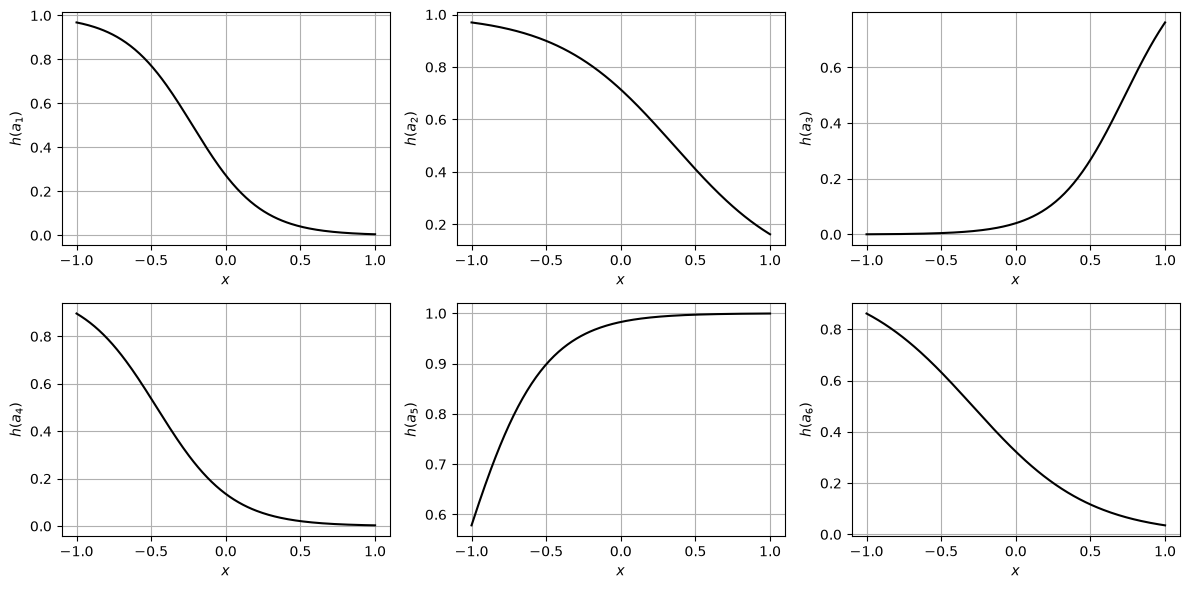

In [2]:
theta_I1, theta_O, theta_I0 = unpack(theta)
fig, axs = plt.subplots(2, 3, figsize=(12, 6))
for j, ax in enumerate(axs.ravel()):
    ax.plot(x_fine, h(theta_I1[j] * x_fine + theta_I0[j]), 'k', linewidth=1.5)
    ax.set_xlabel('$x$'); ax.set_ylabel(rf'$h(a_{j+1})$')
    ax.grid(True)
plt.tight_layout()
plt.show()

Several eigenvalues of the Gauss-Newton Hessian are close to zero: the model is very flexible
and the 20 data points are overfit.

In [3]:
H = sol.jac.T @ sol.jac
print("eigenvalues of H:", np.array2string(np.sort(np.linalg.eigvalsh(H))[::-1], precision=2))

eigenvalues of H: [3.71e+05 9.14e+04 9.44e+03 1.44e+03 2.43e+02 2.52e+01 1.26e+01 2.53e+00
 1.69e-01 2.93e-02 2.86e-03 6.14e-04 9.30e-06 1.00e-07 5.15e-10 9.47e-13
 1.29e-13 7.07e-17]


**Note:** As in the book, the Hessian has eigenvalues near zero: the parameters are not unique and uncertain, so NNs are flexible but prone to overparameterization and overfitting.